# Pokémon Primary Type Prediction

Train a model to predict a Pokémon’s **primary type** from its stats and available attributes. This notebook compares a stats-only model with an expanded model, and reports class-balanced metrics because the type classes are unevenly represented.

> The secondary type can be a very strong clue. The expanded model includes it deliberately; compare it with the stats-only result to see how much that information helps. Features that directly encode type effectiveness are excluded to avoid giving away the answer.

In [17]:
# Setup: import the data, plotting, preprocessing, modeling, and evaluation tools used below.

from pathlib import Path
import ast
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    ConfusionMatrixDisplay, f1_score
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import OneHotEncoder

SEED = 42


## 1. Load and inspect the data

This step brings the Pokémon table into memory and checks its shape, sample rows, and missing values. Upload `All_Pokemon.csv` to the Colab session, or place it beside this notebook; the loader checks both locations.

In [18]:
# Load the CSV from the Colab working folder, or prompt for an upload if it is not there.
# Then inspect a few rows and missing-value counts to understand the input data.

from pathlib import Path
import pandas as pd

candidates = [
    Path('/content/All_Pokemon.csv'),  # Google Colab
    Path('All_Pokemon.csv'),           # Current directory
    Path('data/All_Pokemon.csv')       # VS Code data folder
]

csv_path = next((p for p in candidates if p.exists()), None)

if csv_path is None:
    raise FileNotFoundError(
        "All_Pokemon.csv not found. Please place it in the project folder."
    )

df = pd.read_csv(csv_path)

print(f'Loaded {len(df):,} rows and {len(df.columns)} columns from {csv_path}')

display(df.head())

print('Missing values in key columns:')
display(
    df[['Type 1', 'HP', 'Att', 'Def', 'Spa', 'Spd', 'Spe']]
    .isna()
    .sum()
    .to_frame('missing')
)


Loaded 1,032 rows and 44 columns from data\All_Pokemon.csv


,Number,Name,Type 1,Type 2,Abilities,HP,Att,Def,Spa,Spd,...,Against Bug,Against Rock,Against Ghost,Against Dragon,Against Dark,Against Steel,Against Fairy,Height,Weight,BMI
0,1,Bulbasaur,Grass,Poison,"['Chlorophyll', 'Overgrow']",45,49,49,65,65,...,1.0,1.0,1.0,1.0,1.0,1.0,0.5,0.7,6.9,14.1
1,2,Ivysaur,Grass,Poison,"['Chlorophyll', 'Overgrow']",60,62,63,80,80,...,1.0,1.0,1.0,1.0,1.0,1.0,0.5,1.0,13.0,13.0
2,3,Venusaur,Grass,Poison,"['Chlorophyll', 'Overgrow']",80,82,83,100,100,...,1.0,1.0,1.0,1.0,1.0,1.0,0.5,2.0,100.0,25.0
3,3,Mega Venusaur,Grass,Poison,['Thick Fat'],80,100,123,122,120,...,1.0,1.0,1.0,1.0,1.0,1.0,0.5,2.4,155.5,27.0
4,4,Charmander,Fire,NaN,"['Blaze', 'Solar Power']",39,52,43,60,50,...,0.5,2.0,1.0,1.0,1.0,0.5,0.5,0.6,8.5,23.6


Missing values in key columns:


,missing
Type 1,0
HP,0
Att,0
Def,0
Spa,0
Spd,0
Spe,0


## 2. Prepare features and a stratified holdout

This step separates the answer column (primary type) from the inputs, selects available stats, and reserves a test subset for final evaluation. Stratification preserves type proportions. Missing numeric values and text processing are handled later inside each pipeline, using training data only.

In [19]:
# Select the primary type as the prediction target, choose available input columns,
# convert ability lists to text, and make a stratified train/test split.
# Stratification keeps the type proportions roughly similar in both subsets.

target = 'Type 1' if 'Type 1' in df.columns else 'Type_1'
if target not in df.columns:
    raise ValueError('Could not find the primary type target column.')

stats = [c for c in ['HP', 'Att', 'Def', 'Spa', 'Spd', 'Spe', 'Generation', 'Legendary'] if c in df.columns]
if not stats:
    raise ValueError('No expected numeric stat columns found.')

data = df.loc[df[target].notna()].copy()
data['Abilities_text'] = data.get('Abilities', pd.Series('', index=data.index)).fillna('').astype(str)
if 'Type 2' in data.columns:
    data['Type 2'] = data['Type 2'].fillna('None').astype(str)

X = data[stats + (['Type 2'] if 'Type 2' in data.columns else []) + ['Abilities_text']]
y = data[target].astype(str)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
print(f'Train: {len(X_train):,} | Test: {len(X_test):,} | Types: {y.nunique()}')
print('Numeric features:', stats)


Train: 825 | Test: 207 | Types: 18
Numeric features: ['HP', 'Att', 'Def', 'Spa', 'Spd', 'Spe', 'Generation', 'Legendary']


## Class balance

This step counts each primary type in the training split and plots the counts. Uneven counts can make accuracy misleading, so the evaluation also reports macro F1 and balanced accuracy.

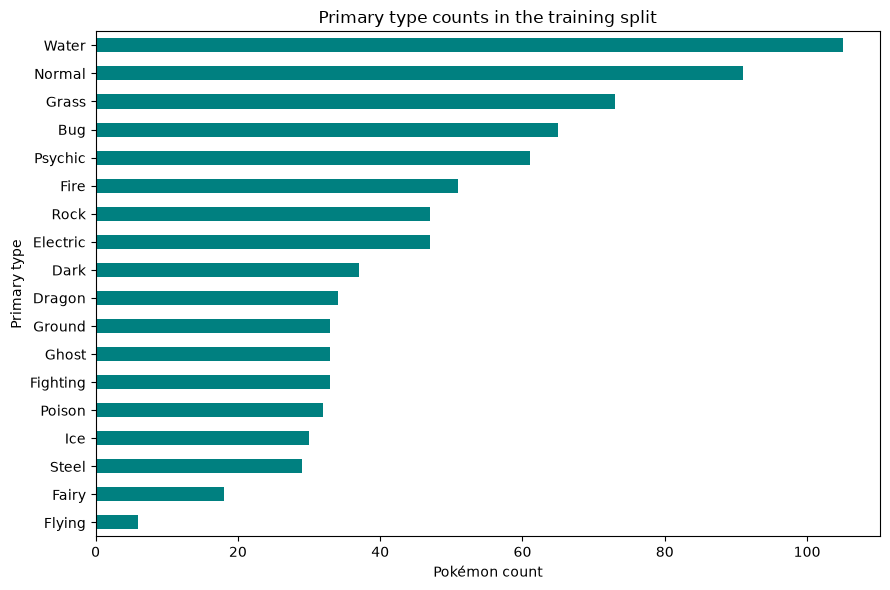

In [20]:
# Plot how many examples of each type are in the training subset. This reveals
# rare classes that can be obscured by overall accuracy.

counts = y_train.value_counts().sort_values()
ax = counts.plot(kind='barh', figsize=(9, 6), color='teal')
ax.set(title='Primary type counts in the training split', xlabel='Pokémon count', ylabel='Primary type')
plt.tight_layout()
plt.show()


## 3. Build and train the models

This step creates a most-frequent baseline and two Random Forest models. The stats-only model uses stats and generation; the expanded model also uses secondary type and abilities. They share the same split and model settings for a fair comparison.

In [21]:
# Define a reusable preprocessing-and-model pipeline. Numeric values are imputed;
# optional type labels are one-hot encoded and ability text is converted to TF-IDF.
# Pipelines fit transformations only on the training data to avoid leakage.

def make_model(include_extra=False):
    numeric = Pipeline([('imputer', SimpleImputer(strategy='median'))])
    transformers = [('numeric', numeric, stats)]
    if include_extra and 'Type 2' in X.columns:
        transformers.append(('type2', OneHotEncoder(handle_unknown='ignore'), ['Type 2']))
    if include_extra:
        transformers.append(('abilities', TfidfVectorizer(max_features=200, token_pattern=r"(?u)\b\w[\w'-]*\b"), 'Abilities_text'))
    preprocess = ColumnTransformer(transformers, remainder='drop')
    return Pipeline([
        ('preprocess', preprocess),
        ('classifier', RandomForestClassifier(
            n_estimators=300, class_weight='balanced_subsample',
            min_samples_leaf=2, random_state=SEED, n_jobs=-1
        ))
    ])

models = {
    'Most-frequent baseline': DummyClassifier(strategy='most_frequent'),
    'Stats only': make_model(False),
    'Stats + secondary type + abilities': make_model(True),
}
for model in models.values():
    model.fit(X_train, y_train)
print('All models trained.')


All models trained.


## Cross-validation on training data

This step evaluates each feature model across five stratified folds of the training data. The test set remains untouched, while fold averages and variation help show whether performance is consistent.

In [22]:
# Compare models across five stratified folds of training data. The mean and spread
# show how stable each model's macro F1 and balanced accuracy are across splits.

from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []
for name in ['Stats only', 'Stats + secondary type + abilities']:
    scores = cross_validate(
        models[name], X_train, y_train, cv=cv,
        scoring={'macro_f1': 'f1_macro', 'balanced_accuracy': 'balanced_accuracy'},
        n_jobs=1
    )
    cv_rows.append({
        'Model': name,
        'Macro F1 (mean ± SD)': f"{scores['test_macro_f1'].mean():.3f} ± {scores['test_macro_f1'].std():.3f}",
        'Balanced accuracy (mean ± SD)': f"{scores['test_balanced_accuracy'].mean():.3f} ± {scores['test_balanced_accuracy'].std():.3f}",
    })
display(pd.DataFrame(cv_rows).set_index('Model'))


,Macro F1 (mean ± SD),Balanced accuracy (mean ± SD)
Model,,
Stats only,0.168 ± 0.028,0.176 ± 0.029
Stats + secondary type + abilities,0.535 ± 0.039,0.550 ± 0.038


## 4. Evaluate on the held-out test set

This step measures predictions on examples the models did not train on. Accuracy is the overall fraction correct; balanced accuracy averages recall by type; macro F1 gives every type equal weight. The report also shows precision, recall, and F1 for each type.

In [23]:
# Predict the untouched test examples and calculate accuracy, balanced accuracy,
# and macro F1. Then print detailed scores for each individual type.

results = []
predictions = {}
for name, model in models.items():
    pred = model.predict(X_test)
    predictions[name] = pred
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Balanced accuracy': balanced_accuracy_score(y_test, pred),
        'Macro F1': f1_score(y_test, pred, average='macro', zero_division=0),
    })
results_df = pd.DataFrame(results).set_index('Model').sort_values('Macro F1', ascending=False)
display(results_df.round(3))

best_name = results_df.index[0]
print(f'Per-type report for: {best_name}')
print(classification_report(y_test, predictions[best_name], zero_division=0))


,Accuracy,Balanced accuracy,Macro F1
Model,,,
Stats + secondary type + abilities,0.633,0.601,0.592
Stats only,0.222,0.224,0.211
Most-frequent baseline,0.126,0.056,0.012


Per-type report for: Stats + secondary type + abilities
              precision    recall  f1-score   support

         Bug       0.75      0.56      0.64        16
        Dark       0.62      0.56      0.59         9
      Dragon       0.56      0.62      0.59         8
    Electric       0.64      0.58      0.61        12
       Fairy       0.50      0.75      0.60         4
    Fighting       0.50      0.67      0.57         9
        Fire       0.92      0.85      0.88        13
      Flying       0.00      0.00      0.00         2
       Ghost       0.86      0.75      0.80         8
       Grass       0.92      0.61      0.73        18
      Ground       0.60      0.38      0.46         8
         Ice       0.67      0.75      0.71         8
      Normal       0.62      0.91      0.74        23
      Poison       0.83      0.62      0.71         8
     Psychic       0.50      0.75      0.60        16
        Rock       0.42      0.42      0.42        12
       Steel       0.36  

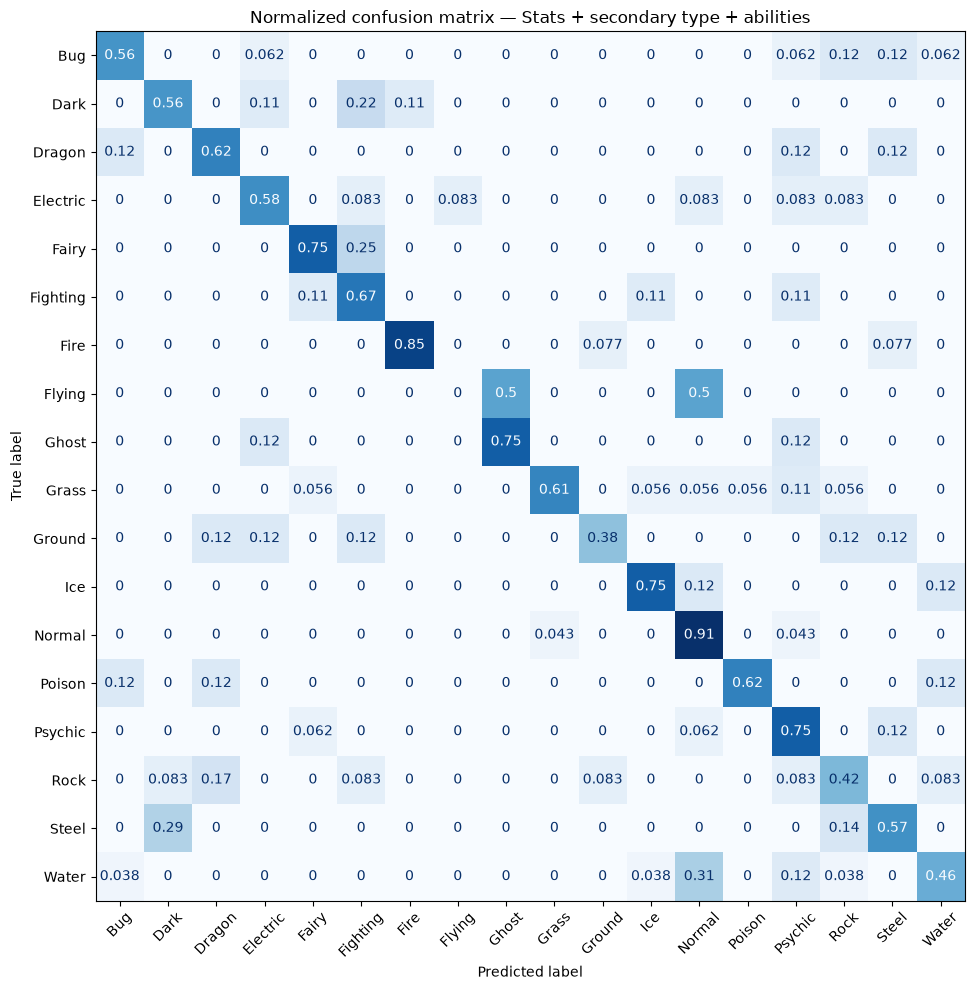

In [24]:
# Display the best model's normalized confusion matrix. Each row is a true type;
# darker cells show where predictions are concentrated.

fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions[best_name], normalize='true',
    xticks_rotation=45, cmap='Blues', colorbar=False, ax=ax
)
ax.set_title(f'Normalized confusion matrix — {best_name}')
plt.tight_layout()
plt.show()


## 5. Interpret the comparison

The expanded model can use secondary type and abilities, which provide additional clues about a Pokémon’s primary type. The stats-only model shows how well primary type can be inferred from battle stats and generation alone. The normalized confusion matrix highlights which types the model most often mixes up.

Results depend on this dataset and the selected train/test split. They show performance on Pokémon represented in this dataset, but do not guarantee performance on future Pokémon.

## What mattered in the stats-only model?

This step plots the stats-only Random Forest's built-in feature importance scores. It describes what this fitted model relied on, but does not show that a feature causes a particular type.

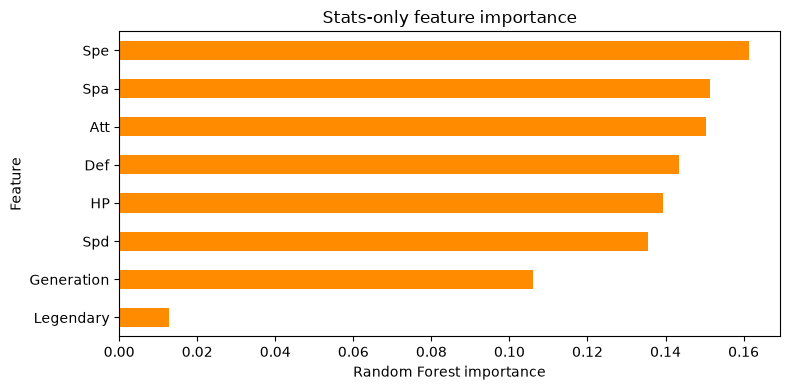

In [25]:
# Rank the stats-only model's inputs by its built-in feature importance scores.
# Higher values mean the model relied more on that feature when making splits.

stats_model = models['Stats only']
importances = stats_model.named_steps['classifier'].feature_importances_
importance = pd.Series(importances, index=stats).sort_values()
ax = importance.plot(kind='barh', figsize=(8, 4), color='darkorange')
ax.set(title='Stats-only feature importance', xlabel='Random Forest importance', ylabel='Feature')
plt.tight_layout()
plt.show()


## 5. Interpret the comparison

Use this step to compare the two feature sets and inspect the normalized confusion matrix. The matrix shows which types the best test-set model confuses; test scores describe this dataset and split, not guaranteed performance on new Pokémon.

## Conclusion

This notebook compares a most-frequent baseline with models trained on stats alone and on stats plus secondary type and abilities. Use the held-out test results to identify which model had the highest macro F1, then report its accuracy and balanced accuracy. Cross-validation provides a check on whether that result is consistent across training-data splits. Feature importance shows which stats the stats-only model relied on most, while the confusion matrix reveals the types it struggled to distinguish.